# Lesson 3 — Model architecture: inside a GPT

⏱ **Duration:** ~35 min &nbsp;|&nbsp; 📚 **Builds on:** Lesson 2 &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- describe embeddings, positional embeddings, attention and the feed-forward block
- explain the causal mask and verify it experimentally
- count parameters per component and relate size to speed

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. The architecture in one picture

```
token ids  (B, T)
   │
   ├─ token embedding   : id  → vector of size n_embd
   ├─ position embedding: position t → vector            (added together)
   ▼
 ┌───────────────────────── × n_layer ─────────────────────────┐
 │  LayerNorm → Causal self-attention → (+ residual)           │
 │  LayerNorm → Feed-forward (Linear, GELU, Linear) → (+ residual) │
 └──────────────────────────────────────────────────────────────┘
   ▼
 LayerNorm → Linear (tied with token embedding) → logits  (B, T, vocab)
```

`B` = batch size, `T` = tokens per sequence. For each of the `T` positions the model outputs
one score per vocabulary word: the **logits**.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
from myllm.model import GPT, GPTConfig
cfg = GPTConfig(vocab_size=4000, block_size=64, n_layer=3, n_head=4, n_embd=128)
model = GPT(cfg)
print(cfg)
print(f"\n{model.num_params():,} parameters")

GPTConfig(vocab_size=4000, block_size=64, n_layer=3, n_head=4, n_embd=128, dropout=0.1)

1,115,264 parameters


## 2. Embeddings: ids become vectors

The embedding is a lookup table of shape `(vocab, n_embd)`. Row `i` is the learned vector for token `i`.
Similar words end up with similar vectors *after training*. A second table adds **position** information, otherwise
"dog bites man" and "man bites dog" would look identical.

In [3]:
x = torch.randint(0, cfg.vocab_size, (2, 10))      # a fake batch: 2 sequences of 10 ids
tok_vec = model.tok_emb(x)
pos_vec = model.pos_emb(torch.arange(10))
print("token embeddings   :", tuple(tok_vec.shape), " (B, T, n_embd)")
print("position embeddings:", tuple(pos_vec.shape), "     (T, n_embd), broadcast over the batch")

token embeddings   : (2, 10, 128)  (B, T, n_embd)
position embeddings: (10, 128)      (T, n_embd), broadcast over the batch


## 3. Self-attention, from scratch

Each position asks: *"which earlier tokens matter for me?"* Concretely, for every token we compute three vectors from its embedding:

* **query** `q` — what I am looking for
* **key** `k` — what I contain
* **value** `v` — what I will pass on

The attention weight of token *i* on token *j* is `softmax(q_i · k_j / √d)`. The output is the weighted sum of the values.

The **causal mask** sets weights for *future* tokens (j > i) to zero: when predicting the next word the model must not peek at it.

row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


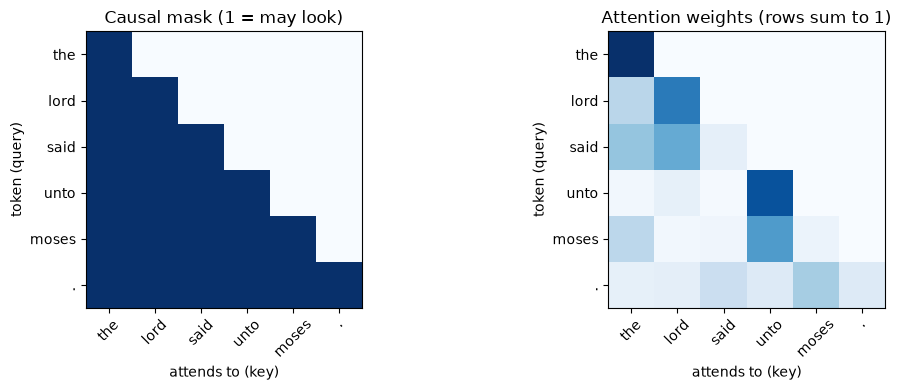

In [4]:
import torch.nn.functional as F
torch.manual_seed(0)
T, d = 6, 16
words = ["the", "lord", "said", "unto", "moses", "."]
emb = torch.randn(T, d)
Wq, Wk, Wv = (torch.randn(d, d) / d**0.5 for _ in range(3))
q, k, v = emb @ Wq, emb @ Wk, emb @ Wv

scores = q @ k.T / d**0.5                                   # (T, T): every token vs every token
mask = torch.tril(torch.ones(T, T)).bool()                   # lower triangle = allowed
weights = F.softmax(scores.masked_fill(~mask, float("-inf")), dim=-1)
out = weights @ v

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m, title in ((ax[0], mask.float(), "Causal mask (1 = may look)"), (ax[1], weights, "Attention weights (rows sum to 1)")):
    im = a.imshow(m, cmap="Blues"); a.set(title=title, xticks=range(T), yticks=range(T))
    a.set_xticklabels(words, rotation=45); a.set_yticklabels(words); a.grid(False)
    a.set_xlabel("attends to (key)"); a.set_ylabel("token (query)")
plt.tight_layout()
print("row sums:", weights.sum(-1))

**Multi-head attention** runs several smaller attentions in parallel (here `n_head=4`), each free to learn a different relation
(e.g. *previous word*, *matching quote*, *subject of the verb*), then concatenates the results.

## 4. Proof: the model cannot see the future

If we change tokens *after* position 8, the logits for positions *before* 8 must not change.

In [5]:
model.eval()
a = torch.randint(0, cfg.vocab_size, (1, 12))
b = a.clone(); b[0, 8:] = (b[0, 8:] + 1) % cfg.vocab_size      # change only the future
with torch.no_grad():
    la, lb = model(a)[0], model(b)[0]
print("positions 0-7 unchanged :", torch.allclose(la[:, :8], lb[:, :8], atol=1e-5))
print("positions 8-11 changed  :", not torch.allclose(la[:, 8:], lb[:, 8:]))

positions 0-7 unchanged : True
positions 8-11 changed  : True


## 5. Where are the parameters?

Parameters are the numbers that training adjusts. Let's count them per component.

token embedding (shared with output)        512,000   45.9%
feed-forward                                395,136   35.4%
attention                                   198,144   17.8%
position embedding                            8,192    0.7%
layer norms                                   1,792    0.2%
TOTAL                                     1,115,264


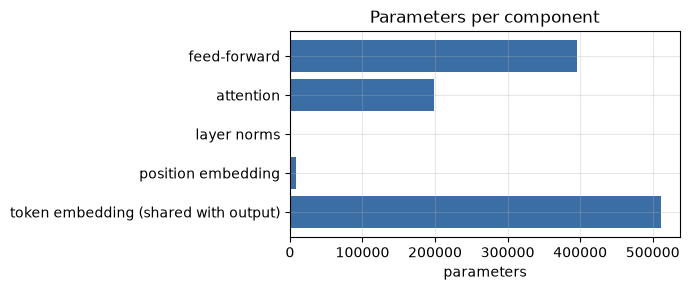

In [6]:
groups = {}
for name, p in model.named_parameters():
    key = ("token embedding (shared with output)" if name.startswith("tok_emb") else
           "position embedding" if name.startswith("pos_emb") else
           "attention" if ".attn." in name else
           "feed-forward" if ".mlp." in name else
           "layer norms")
    groups[key] = groups.get(key, 0) + p.numel()
for k_, v_ in sorted(groups.items(), key=lambda kv: -kv[1]):
    print(f"{k_:40s} {v_:10,d}  {v_ / model.num_params():6.1%}")
print(f"{'TOTAL':40s} {model.num_params():10,d}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(list(groups), list(groups.values()), color="#3b6ea5"); ax.set(title="Parameters per component", xlabel="parameters")
plt.tight_layout()

> 💬 **Discussion:** the embedding table is the biggest part! With a small model most weights sit in the vocabulary,
> not in the transformer layers. *Weight tying* (reusing the embedding as the output layer) saves one more table of the same size.

## 6. Size vs. speed — measured

Doubling width or depth costs time. We time one training step for a few shapes.

2 layers, 64 wide       360,192 params      78 ms/step
3 layers, 128 wide    1,115,264 params     171 ms/step
6 layers, 128 wide    1,710,080 params     267 ms/step
3 layers, 256 wide    3,410,176 params     352 ms/step


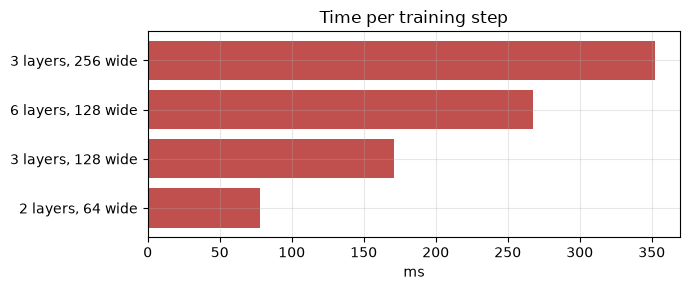

In [7]:
import time
def ms_per_step(**kw):
    m = GPT(GPTConfig(vocab_size=4000, block_size=kw.pop("block_size", 64), **kw))
    opt = torch.optim.AdamW(m.parameters()); x = torch.randint(0, 4000, (16, m.cfg.block_size))
    for i in range(6):
        if i == 2: t0 = time.time()
        _, l = m(x, x); opt.zero_grad(); l.backward(); opt.step()
    return m.num_params(), (time.time() - t0) / 4 * 1000

configs = {"2 layers, 64 wide": dict(n_layer=2, n_head=2, n_embd=64),
           "3 layers, 128 wide": dict(n_layer=3, n_head=4, n_embd=128),
           "6 layers, 128 wide": dict(n_layer=6, n_head=4, n_embd=128),
           "3 layers, 256 wide": dict(n_layer=3, n_head=4, n_embd=256)}
res = {k_: ms_per_step(**v_) for k_, v_ in configs.items()}
for k_, (p, ms) in res.items():
    print(f"{k_:20s} {p:10,d} params  {ms:6.0f} ms/step")
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(list(res), [r[1] for r in res.values()], color="#c0504d"); ax.set(title="Time per training step", xlabel="ms")
plt.tight_layout()

---
## ✅ Key takeaways

- Embeddings turn ids into vectors; position embeddings tell the model word order.
- Self-attention lets each token gather information from *earlier* tokens; the causal mask forbids peeking ahead.
- A GPT is just `n_layer` repeated blocks of attention + feed-forward with residual connections.
- Cost grows with width, depth and vocabulary; in small models the vocabulary dominates the parameters.

## 🧪 Exercises

1. Change `T` and the sentence in the attention demo. Remove the mask: what changes in the heatmap?
2. Build `GPTConfig(n_head=3, n_embd=128)`. What error do you get and why?
3. Estimate how many parameters a 12-layer, 768-wide model with a 50,000-word vocabulary has (this is GPT-2 small, ~124M).

## ➡️ Next

**Lesson 4 — Training:** how these random weights become a language model.